# Does mixing PE and TI reduce hedging-cost variance?

Compare three portfolios of 1,000 distinct policyholders, all aged 60:
1,000 PE; 1,000 TI; and 500 PE plus 500 TI. Each portfolio has total notional
one, so every individual has notional 0.001. Market, carbon, mortality model,
initial valuation and revaluation settings remain common.

The mixed portfolio is simulated directly with independent lifetimes for its
PE and TI policyholders. An average of the pure portfolio cost arrays would
instead place both contracts on the same lives and is not this experiment.
Pure and mixed portfolios can have different initial premiums; each is funded
with its own computed premium and hedged using its own aggregate delta.

Each explanation cell is followed by its Python cell. Every experiment input
is explicit and editable. Defaults use the same paper calibration as the
preceding notebook and your recent numerical budgets. Costs use the current
time-zero accounting, with positive values meaning additional funding.
No variance reduction is assumed in advance.

Save under `CarbonFund_UL/notebooks/`, select the `.venv-analysis` kernel,
and run in order. To reload saved CSVs later, set `RUN_SIMULATIONS=False` and
retain the run name and simulation inputs. Use a new run name when changing
simulation settings. The existing OpenMP-enabled C++ runner performs all
simulations; this notebook does not change the library.


In [1]:
from pathlib import Path
from copy import deepcopy
import csv
import html
import json
import math
import sys

PROJECT_ROOT = Path('/home/edoardolombardo/Documents/codes/CarbonFund_UL')
BINARY = PROJECT_ROOT / 'build-paper-release' / 'carbonfund_experiment'
OUTPUT_ROOT = PROJECT_ROOT / 'results' / 'mixed_pe_ti'
RUN_NAME = 'cir_T20_PE_TI_500_500_01'
RUN_SIMULATIONS = True
OVERWRITE_EXISTING = False
SAVE_FIGURES = True
SHOW_FIGURES = True

sys.path.insert(0, str(PROJECT_ROOT / 'python'))
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from IPython.display import HTML, display
import carbonfund_experiments as cfe

RUN_DIRECTORY = OUTPUT_ROOT / RUN_NAME
if RUN_SIMULATIONS and not BINARY.is_file():
    raise FileNotFoundError(f'Build carbonfund_experiment first: {BINARY}')
print('Python module:', Path(cfe.__file__).resolve())
print('Output directory:', RUN_DIRECTORY)


Python module: /home/edoardolombardo/Documents/codes/CarbonFund_UL/python/carbonfund_experiments.py
Output directory: /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/mixed_pe_ti/cir_T20_PE_TI_500_500_01


**Market inputs.** There are exactly four stocks. Returns and volatilities are
annualized; the risk-free rate is continuously compounded. The correlation
matrix must be symmetric and positive definite with unit diagonal. The code
constructs covariance from volatilities and correlations. These are the
full-precision legacy correlations; Table 4.1 prints rounded entries.


In [2]:
market = {
    'risk_free_rate': 0.05,
    'expected_returns': [0.25, 0.15, 0.10, 0.08],
    'volatilities': [0.30, 0.25, 0.20, 0.16],
    'correlations': [
        [1.0000, 0.4397, 0.3900, 0.3168],
        [0.4397, 1.0000, 0.2954, 0.3261],
        [0.3900, 0.2954, 1.0000, 0.3134],
        [0.3168, 0.3261, 0.3134, 1.0000],
    ],
}


**Carbon inputs.** The paper uses four CIR intensities,
$dC_i=\kappa_i(\theta_i-C_i)dt+\sigma_i\sqrt{C_i}\,dB_i$,
simulated by the library's CIR scheme. All four entries can be changed.
The other supported model names are `OU` and `GeoOU`.
OU uses the same parameter keys with additive noise. GeoOU models the log
intensity as OU; replace `long_run_mean` with `long_run_log_mean` when selecting
it, and keep initial intensities positive. For CIR, initial and long-run
intensities are nonnegative. Stocks share the chosen market correlations;
the current carbon components and financial innovations are independent.


In [3]:
carbon = {
    'model': 'CIR',
    'initial': [5000.0, 4000.0, 3000.0, 1000.0],
    'long_run_mean': [2500.0, 2000.0, 1500.0, 500.0],
    'mean_reversion': [0.05, 0.05, 0.05, 0.05],
    'volatility': [3.0, 3.0, 3.0, 3.0],
}


**Fund inputs.** Risk aversion and carbon penalization determine the fund's
stock weights from the observed carbon state. Larger carbon penalization
discourages exposure to carbon-intensive stocks. These preferences and the
market/carbon inputs remain common to all portfolio sizes and contract types.


In [4]:
fund = {
    'risk_aversion': 1.0,
    'carbon_penalty': 0.0025,
}


**Contract inputs.** The benefit at elapsed time $t$ is
$\min(U_0e^{g_Ut},\max(L_0e^{g_Lt},X_t))$ per unit of notional.
PE pays on survival at maturity; TI pays on death before maturity; EI combines
survival payment and a death payment multiplied by the death-benefit fraction.
These are nominal benefits, discounted once in present-value costs.
Guarantees stay anchored to these original terms when the observed fund changes.
`fund_value` is the initial unit fund value, not the portfolio's total notional.
The growth rates are explicit inputs; changing the market rate does not
automatically change them.


In [5]:
contract = {
    'fund_value': 1.0,
    'maturity': 20.0,
    'minimum_guarantee': 1.0,
    'maximum_guarantee': 1.0,
    'minimum_guarantee_growth_rate': 0.05,
    'maximum_guarantee_growth_rate': 0.50,
    'endowment_death_benefit_fraction': 1.0,
}


**Mortality inputs.** For a policyholder aged $a$ initially,
$\mu(a+t)=\xi+b^{-1}\exp((a+t-m)/b)$.
This uses the corrected minus sign and $\xi=0.0041959$.
The scale is `b`, not its reciprocal. Lifetimes are independent across
policyholders under this deterministic mortality law; there is no common
stochastic mortality factor in this experiment.


In [6]:
mortality = {
    'xi': 0.0041959,
    'm': 79.6921211,
    'b': 11.5818911,
}


**Portfolio composition and exposure.** The counts below specify the actual
insured lives, not weights applied to existing cost distributions. All three
portfolios use the same age and total notional. Their policy counts must agree
so that each policy has the same notional and portfolio size does not confound
composition. In the default mix, the PE and TI groups each carry notional 0.5.
All lifetimes are independent within each portfolio under the mortality model.

The input order is PE lives followed by TI lives. With the same seeds and age,
the current sampler uses the same indexed lifetimes across the alternative
portfolios; assigning a different contract does not change a life. PE and TI
groups inside the mixed portfolio still consist of different people.


In [7]:
POLICYHOLDER_AGE = 60.0
TOTAL_NOTIONAL = 1.0
PORTFOLIOS = {
    'pure_PE': {'PE': 1000, 'TI': 0},
    'pure_TI': {'PE': 0, 'TI': 1000},
    'mixed': {'PE': 500, 'TI': 500},
}
PE_REFERENCE = 'pure_PE'
TI_REFERENCE = 'pure_TI'
MIXED_PORTFOLIO = 'mixed'

if not math.isfinite(TOTAL_NOTIONAL) or TOTAL_NOTIONAL <= 0:
    raise ValueError('TOTAL_NOTIONAL must be finite and positive.')
if any(key not in PORTFOLIOS for key in (PE_REFERENCE, TI_REFERENCE, MIXED_PORTFOLIO)):
    raise ValueError('Reference and mixed portfolio IDs must exist.')
for counts in PORTFOLIOS.values():
    if set(counts) != {'PE', 'TI'} or any(
        isinstance(n, bool) or not isinstance(n, int) or n < 0 for n in counts.values()
    ):
        raise ValueError('Each portfolio needs nonnegative integer PE and TI counts.')
counts_per_portfolio = {key: sum(counts.values()) for key, counts in PORTFOLIOS.items()}
if len(set(counts_per_portfolio.values())) != 1 or next(iter(counts_per_portfolio.values())) < 1:
    raise ValueError('Use the same positive total policy count in every portfolio.')
if PORTFOLIOS[PE_REFERENCE]['TI'] or PORTFOLIOS[TI_REFERENCE]['PE']:
    raise ValueError('The reference portfolios must be pure PE and pure TI.')
if min(PORTFOLIOS[MIXED_PORTFOLIO].values()) < 1:
    raise ValueError('The mixed portfolio must contain both PE and TI lives.')

POLICY_COUNT = next(iter(counts_per_portfolio.values()))
NOTIONAL_PER_POLICY = TOTAL_NOTIONAL / POLICY_COUNT
populations = {
    key: [
        {'type': kind, 'age': POLICYHOLDER_AGE, 'notional': NOTIONAL_PER_POLICY}
        for kind in ('PE', 'TI') for _ in range(counts[kind])
    ]
    for key, counts in PORTFOLIOS.items()
}
portfolio_labels = {
    key: ' + '.join(f'{count:,} {kind}' for kind, count in counts.items() if count)
    for key, counts in PORTFOLIOS.items()
}
print('Lives in each portfolio:', POLICY_COUNT)
print('Notional per life:', NOTIONAL_PER_POLICY)
for key, counts in PORTFOLIOS.items():
    print(portfolio_labels[key], {kind: count * NOTIONAL_PER_POLICY for kind, count in counts.items()})


Lives in each portfolio: 1000
Notional per life: 0.001
1,000 PE {'PE': 1.0, 'TI': 0.0}
1,000 TI {'PE': 0.0, 'TI': 1.0}
500 PE + 500 TI {'PE': 0.5, 'TI': 0.5}


**Outer simulation inputs.** Each scenario has one common carbon/fund path and
mortality draws for the indexed lives. Identical seeds, market inputs and grids
are reused across the portfolio compositions, giving paired outcomes for the
comparison. Each outer CSV row is independent of other rows. The inner
antithetic choice does not make the outer rows antithetic.
`threads=16` parallelizes outer scenarios in C++; zero uses the OpenMP runtime
limit. Progress is printed every `progress_every` completed scenarios and at
completion. These numerical budgets are editable starting choices.


In [8]:
outer_simulation = {
    'outer_scenarios': 1000,
    'intervals': 1040,
    'progress_every': 200,
    'threads': 16,
    'carbon_seed': 2026101801,
    'financial_seed': 2026101802,
    'mortality_seed': 2026101803,
}


**Initial valuation inputs.** Compute the initial premium and the PE/TI delta
components for each actual portfolio. All runs use common initial pricing
seeds. Linearity implies that the default mixed premium is half the pure PE
premium plus half the pure TI premium; the same weighted relation holds for
the initial delta vector. The notebook checks this identity.
Available configurations are `standard`, `standard_antithetic`, `conditioned`
and `conditioned_antithetic`. With antithetics, 4,000 paths are 2,000 pair means.


In [9]:
initial_valuation = {
    'paths': 1600,
    'intervals': 1040,
    'configuration': 'conditioned_antithetic',
    'carbon_seed': 2026101804,
    'financial_seed': 2026101805,
}


**Revaluation inputs.** Reprice the surviving liabilities and compute deltas
at each intermediate outer date. The number of inner intervals is
$\max(N_{\min},\lceil N_{\mathrm{base}}(T-t)/T\rceil)$.
`minimum_intervals` must be between 1 and `intervals`; making both 256 fixes
the count at 256. These are inner pricing intervals, independent of the outer
hedge dates. The configuration below keeps your recent fixed-grid comparison
explicit. The minimum setting requires the updated experiment interface.
Choose a new output run name after changing it.


In [10]:
revaluation = {
    'paths': 40,
    'intervals': 256,
    'minimum_intervals': 1,
    'configuration': 'conditioned_antithetic',
    'carbon_seed': 2026101806,
    'financial_seed': 2026101807,
}


**Analysis inputs.** All comparisons use the same selected cost units.
`per_notional` divides costs by total portfolio notional; `aggregate` reports
total monetary costs and `per_policy` divides by the number of lives.
Equal counts and total notionals make variance ratios invariant to these
common scaling conventions. Variance uses `ddof=1`.
Mean intervals are conditional on the computed initial valuations. The family
size below applies to strategy contrasts within the saved run summaries;
the bootstrap intervals for portfolio variance comparisons below are individual
intervals, without a simultaneous multiple-comparison adjustment.


In [11]:
analysis = {
    'normalization': 'per_notional',
    'confidence_level': 0.95,
    'comparison_family_size': 9,
    'quantiles': [0.025, 0.50, 0.90, 0.95, 0.975, 0.99],
    'expected_shortfall_levels': [0.95, 0.99],
    'bins': 100,
    'zoom': None,
    'plot_range': None,
    'figure_formats': ['png', 'pdf'],
    'dpi': 180,
    'title': 'Mixed PE/TI portfolio: equal total notional',
}
DISPLAY_DECIMALS = 4


**Bootstrap inputs.** Resample scenario rows with replacement to measure
uncertainty in the mixed-versus-pure variance ratios. The same resampled row
indices are used for every portfolio and strategy, preserving their paired
dependence. This reuses saved costs and does not rerun C++.
Percentile intervals use `analysis['confidence_level']`. A positive lower
bound for variance reduction supports a reduction at that individual nominal
confidence level. Intervals containing zero are inconclusive. Bootstrap
uncertainty is conditional on the valuations and discretization used in the run.


In [12]:
bootstrap_settings = {
    'enabled': True,
    'repetitions': 2000,
    'seed': 2026102101,
    'chunk_size': 64,
}
if (not isinstance(bootstrap_settings['repetitions'], int)
        or bootstrap_settings['repetitions'] < 100):
    raise ValueError('Use at least 100 bootstrap repetitions.')
if (not isinstance(bootstrap_settings['chunk_size'], int)
        or bootstrap_settings['chunk_size'] < 1):
    raise ValueError('Bootstrap chunk size must be a positive integer.')


**Plot inputs.** The default focuses on dynamic hedging cost. Add `no_hedge`
and `static_hedge` to see the other strategies too. Density plots overlay the
three real portfolios. Histograms use each sample's full range and integrate
to one; KDE is an optional smooth estimate. Optional x limits crop the view
without changing statistics or renormalizing the data. Variance plots and
variance reduction intervals are computed from complete samples.


In [13]:
plot_settings = {
    'strategies': ['dynamic_hedge'],
    'density_method': 'histogram',  # 'histogram' or 'kde'
    'kde_bandwidth': 'scott',
    'density_grid_points': 2048,
    'histogram_alpha': 0.40,
    'line_width': 1.8,
    'panel_size': [6.0, 4.5],
    'x_limits': {'no_hedge': None, 'static_hedge': None, 'dynamic_hedge': None},
    'colors': ['#0072B2', '#D55E00', '#009E73', '#CC79A7'],
    'boxplot_show_fliers': True,
    'boxplot_whiskers': 1.5,
    'variance_log_scale': False,
}
if (not plot_settings['strategies']
        or len(set(plot_settings['strategies'])) != len(plot_settings['strategies'])
        or any(s not in cfe.STRATEGIES for s in plot_settings['strategies'])):
    raise ValueError('Select distinct supported hedging strategies.')
if plot_settings['density_method'] not in ('histogram', 'kde'):
    raise ValueError('Unknown density method.')


**Assemble and audit.** Create one complete configuration for each actual
population. All other inputs are copied identically, including seeds.
Rerun this cell after editing any earlier model or simulation inputs.
The mixed portfolio is passed directly to the existing C++ hedging engine.


In [14]:
configs = {}
for key, people in populations.items():
    cfg = {
        'schema_version': 1, 'experiment': 'hedging',
        'market': deepcopy(market), 'carbon': deepcopy(carbon),
        'fund': deepcopy(fund), 'contract': deepcopy(contract),
        'mortality': deepcopy(mortality), 'population': deepcopy(people),
        'hedging': {**deepcopy(outer_simulation),
                    'initial': deepcopy(initial_valuation),
                    'revaluation': deepcopy(revaluation)},
        'analysis': deepcopy(analysis),
        'notes': 'Actual mixed PE/TI population; equal total notional and size; shared scenario streams.',
    }
    cfe.validate_config(cfg)
    configs[key] = cfg
audit = {
    'portfolios': PORTFOLIOS, 'age': POLICYHOLDER_AGE,
    'total_notional': TOTAL_NOTIONAL, 'notional_per_policy': NOTIONAL_PER_POLICY,
    'normalization': analysis['normalization'], 'outer_simulation': outer_simulation,
    'initial_valuation': initial_valuation, 'revaluation': revaluation,
}
print(json.dumps(audit, indent=2))


{
  "portfolios": {
    "pure_PE": {
      "PE": 1000,
      "TI": 0
    },
    "pure_TI": {
      "PE": 0,
      "TI": 1000
    },
    "mixed": {
      "PE": 500,
      "TI": 500
    }
  },
  "age": 60.0,
  "total_notional": 1.0,
  "notional_per_policy": 0.001,
  "normalization": "per_notional",
  "outer_simulation": {
    "outer_scenarios": 1000,
    "intervals": 1040,
    "progress_every": 200,
    "threads": 16,
    "carbon_seed": 2026101801,
    "financial_seed": 2026101802,
    "mortality_seed": 2026101803
  },
  "initial_valuation": {
    "paths": 1600,
    "intervals": 1040,
    "configuration": "conditioned_antithetic",
    "carbon_seed": 2026101804,
    "financial_seed": 2026101805
  },
  "revaluation": {
    "paths": 40,
    "intervals": 256,
    "minimum_intervals": 1,
    "configuration": "conditioned_antithetic",
    "carbon_seed": 2026101806,
    "financial_seed": 2026101807
  }
}


**Run or reload the three portfolios.** Each directory contains raw aggregate
`hedging.csv`, exact inputs, metadata, and strategy statistics. The common
market streams are independent of inner pricing streams. Reloading with
`RUN_SIMULATIONS=False` checks the saved simulation inputs; analysis and plot
choices may change. The combined analysis below is saved at the run root.


In [15]:
def simulation_inputs(cfg):
    inputs = deepcopy({k: v for k, v in cfg.items() if k not in ('analysis', 'notes')})
    inputs['hedging']['revaluation'].setdefault('minimum_intervals', 1)
    return inputs

results = {}
for key, cfg in configs.items():
    destination = RUN_DIRECTORY / key
    print(f'\n{portfolio_labels[key]} -> {destination}', flush=True)
    if RUN_SIMULATIONS:
        result = cfe.run_experiment(cfg, destination, binary=BINARY,
            overwrite=OVERWRITE_EXISTING, plots=False, progress=True)
    else:
        result = cfe.load_result(destination)
        if simulation_inputs(result.config) != simulation_inputs(cfg):
            raise ValueError(f'{key}: saved and current simulation inputs differ.')
        result.config['analysis'] = deepcopy(analysis)
        result.save_analysis(plots=False)
    results[key] = result
    run = result.metadata['run']
    print('Initial premium:', run['initial_price'])
    print('Initial deltas PE/TI/EI:', run['initial_deltas_PE_TI_EI'])
    print('Actual threads:', run['threads_used'])
    print('Outer elapsed seconds:', run['simulation_wall_seconds'])

RUN_DIRECTORY.mkdir(parents=True, exist_ok=True)
manifest = {**audit, 'analysis': deepcopy(analysis),
            'bootstrap_settings': deepcopy(bootstrap_settings),
            'plot_settings': deepcopy(plot_settings),
            'model_inputs': {k: deepcopy(next(iter(configs.values()))[k])
                             for k in ('market', 'carbon', 'fund', 'contract', 'mortality')},
            'run_directories': {key: str(r.directory.relative_to(RUN_DIRECTORY))
                                for key, r in results.items()}}
(RUN_DIRECTORY / 'mixed_portfolio_manifest.json').write_text(json.dumps(manifest, indent=2) + '\n')



1,000 PE -> /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/mixed_pe_ti/cir_T20_PE_TI_500_500_01/pure_PE
Hedging scenarios completed: 200/1000
Hedging scenarios completed: 400/1000
Hedging scenarios completed: 600/1000
Hedging scenarios completed: 800/1000
Hedging scenarios completed: 1000/1000
Saved experiment to /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/mixed_pe_ti/cir_T20_PE_TI_500_500_01/pure_PE
Initial premium: 0.48398407988818104
Initial deltas PE/TI/EI: [0.24199203994409052, 0.0, 0.0]
Actual threads: 16
Outer elapsed seconds: 225.362846207

1,000 TI -> /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/mixed_pe_ti/cir_T20_PE_TI_500_500_01/pure_TI
Hedging scenarios completed: 200/1000
Hedging scenarios completed: 400/1000
Hedging scenarios completed: 600/1000
Hedging scenarios completed: 800/1000
Hedging scenarios completed: 1000/1000
Saved experiment to /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/mixed_pe_ti/cir_T20_PE_TI_5

3653

**Check fairness and initial linearity.** All portfolios must have the same
scenario IDs, terminal fund values, policy count and total notional. Initial
premiums and delta vectors must follow the weighted PE/TI relation implied
by the counts. Final costs are not expected to equal a weighted average of
pure portfolio costs, because the mixed portfolio assigns contracts to
distinct subsets of people. Mortality risk inside those subsets is sampled.


In [16]:
def read_raw(result):
    with (result.directory / 'hedging.csv').open(newline='') as stream:
        rows = list(csv.DictReader(stream))
    return {key: np.array([float(row[key]) for row in rows]) for key in rows[0]}

raw = {key: read_raw(r) for key, r in results.items()}
reference_raw = raw[PE_REFERENCE]
pe_run = results[PE_REFERENCE].metadata['run']
ti_run = results[TI_REFERENCE].metadata['run']
for key, result in results.items():
    assert result.metadata['policy_count'] == POLICY_COUNT
    np.testing.assert_allclose(result.metadata['total_notional'], TOTAL_NOTIONAL,
                               rtol=1e-12, atol=1e-14)
    np.testing.assert_array_equal(raw[key]['scenario_id'], reference_raw['scenario_id'])
    np.testing.assert_array_equal(raw[key]['fund_terminal'], reference_raw['fund_terminal'])
    weight_pe = PORTFOLIOS[key]['PE'] / POLICY_COUNT
    weight_ti = PORTFOLIOS[key]['TI'] / POLICY_COUNT
    target_price = weight_pe * pe_run['initial_price'] + weight_ti * ti_run['initial_price']
    target_deltas = (weight_pe * np.array(pe_run['initial_deltas_PE_TI_EI'])
                     + weight_ti * np.array(ti_run['initial_deltas_PE_TI_EI']))
    np.testing.assert_allclose(result.metadata['run']['initial_price'], target_price,
                               rtol=1e-10, atol=1e-12)
    np.testing.assert_allclose(result.metadata['run']['initial_deltas_PE_TI_EI'],
                               target_deltas, rtol=1e-10, atol=1e-12)
print('Equal exposure, common market scenarios and initial price/delta linearity: verified.')


Equal exposure, common market scenarios and initial price/delta linearity: verified.


**Full statistics in common units.** Means, variances, standard deviations,
mean intervals, quantiles and expected shortfalls are saved for every
portfolio and all three hedging strategies. Floating statistics display in
scientific notation with four decimals; CSV values retain full precision.


In [17]:
def write_rows(path, rows):
    with Path(path).open('w', newline='') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

def show_rows(rows):
    def format_value(key, value):
        if isinstance(value, (float, np.floating)):
            return (f'{value:.4f}%' if key.endswith('_percent')
                    else f'{value:.{DISPLAY_DECIMALS}e}')
        return html.escape(str(value))
    heads = ''.join(f'<th>{html.escape(key)}</th>' for key in rows[0])
    body = ''.join('<tr>' + ''.join(f'<td>{format_value(k, v)}</td>'
                   for k, v in row.items()) + '</tr>' for row in rows)
    display(HTML('<div style="overflow:auto"><table><thead><tr>' + heads
                 + '</tr></thead><tbody>' + body + '</tbody></table></div>'))

summaries = {key: result.summary() for key, result in results.items()}
summary_lookup = {(key, row['strategy']): row
                  for key, rows in summaries.items() for row in rows}
summary_rows = [{'portfolio': portfolio_labels[key], 'portfolio_id': key,
                 'policy_count': result.metadata['policy_count'],
                 'total_notional': result.metadata['total_notional'],
                 'normalization': analysis['normalization'], **row}
                for key, result in results.items() for row in summaries[key]]
show_rows(summary_rows)
write_rows(RUN_DIRECTORY / 'portfolio_summary.csv', summary_rows)

portfolio_order = list(results)
normalized_costs = {}
for key, result in results.items():
    divisor = {'aggregate': 1.0, 'per_policy': result.metadata['policy_count'],
               'per_notional': result.metadata['total_notional']}[analysis['normalization']]
    normalized_costs[key] = result.costs / divisor
cost_cube = np.stack([normalized_costs[key] for key in portfolio_order], axis=1)
variance_estimates = np.var(cost_cube, axis=0, ddof=1)


portfolio,portfolio_id,policy_count,total_notional,normalization,strategy,n,mean,variance,std,mean_se,mean_ci_low,mean_ci_high,min,max,probability_positive,q2.5,q50,q90,q95,q97.5,q99,es95,es99
"1,000 PE",pure_PE,1000,1.0000e+00,per_notional,no_hedge,1000,1.1558e+00,1.1126e+00,1.0548e+00,3.3356e-02,1.0904e+00,1.2213e+00,-1.0898e-01,9.2909e+00,9.7000e-01,-8.1331e-03,9.0129e-01,2.3746e+00,3.0746e+00,3.7378e+00,5.2315e+00,4.3599e+00,6.6997e+00
"1,000 PE",pure_PE,1000,1.0000e+00,per_notional,static_hedge,1000,6.6715e-01,4.6648e-01,6.8299e-01,2.1598e-02,6.2477e-01,7.0953e-01,-1.3027e-01,6.1926e+00,9.3300e-01,-5.8619e-02,5.0872e-01,1.4299e+00,1.8531e+00,2.3443e+00,3.3657e+00,2.7652e+00,4.3701e+00
"1,000 PE",pure_PE,1000,1.0000e+00,per_notional,dynamic_hedge,1000,-5.8693e-04,2.5734e-03,5.0728e-02,1.6042e-03,-3.7349e-03,2.5610e-03,-2.3234e-01,2.3330e-01,5.0000e-01,-1.1806e-01,2.9518e-05,5.7001e-02,7.5482e-02,9.2792e-02,1.2329e-01,1.0688e-01,1.5982e-01
"1,000 TI",pure_TI,1000,1.0000e+00,per_notional,no_hedge,1000,6.8845e-01,3.0906e-01,5.5594e-01,1.7580e-02,6.5395e-01,7.2294e-01,-9.6270e-02,3.4713e+00,9.6900e-01,-1.3345e-02,5.7476e-01,1.3876e+00,1.7622e+00,2.1323e+00,2.5579e+00,2.2907e+00,3.0333e+00
"1,000 TI",pure_TI,1000,1.0000e+00,per_notional,static_hedge,1000,-1.3299e-02,3.1035e-02,1.7617e-01,5.5709e-03,-2.4231e-02,-2.3669e-03,-1.1165e+00,1.1634e+00,4.3600e-01,-3.6584e-01,-1.8521e-02,1.7731e-01,2.5439e-01,3.3837e-01,4.7371e-01,3.9741e-01,6.5194e-01
"1,000 TI",pure_TI,1000,1.0000e+00,per_notional,dynamic_hedge,1000,9.2109e-04,2.5361e-03,5.0359e-02,1.5925e-03,-2.2039e-03,4.0461e-03,-2.3845e-01,2.3956e-01,4.9400e-01,-9.1982e-02,-9.1005e-04,5.9261e-02,8.4902e-02,1.2216e-01,1.5381e-01,1.2790e-01,1.8392e-01
500 PE + 500 TI,mixed,1000,1.0000e+00,per_notional,no_hedge,1000,9.1983e-01,6.1462e-01,7.8398e-01,2.4792e-02,8.7118e-01,9.6848e-01,-9.9659e-02,6.1780e+00,9.7400e-01,-1.5727e-03,7.3161e-01,1.8965e+00,2.3578e+00,2.8857e+00,3.8046e+00,3.2634e+00,4.8204e+00
500 PE + 500 TI,mixed,1000,1.0000e+00,per_notional,static_hedge,1000,3.2449e-01,1.0514e-01,3.2425e-01,1.0254e-02,3.0437e-01,3.4462e-01,-8.8422e-02,2.7157e+00,9.2500e-01,-4.5995e-02,2.5064e-01,7.2960e-01,9.1640e-01,1.1478e+00,1.4746e+00,1.2947e+00,1.9789e+00
500 PE + 500 TI,mixed,1000,1.0000e+00,per_notional,dynamic_hedge,1000,-1.4876e-03,2.8153e-03,5.3059e-02,1.6779e-03,-4.7802e-03,1.8050e-03,-2.6348e-01,2.9850e-01,4.9800e-01,-1.1401e-01,-2.0212e-04,5.7762e-02,7.9848e-02,9.9187e-02,1.2957e-01,1.1544e-01,1.8224e-01


**Variance reduction against each pure portfolio.** For a reference variance
$v_R$, the reduction is $100(1-v/v_R)$. The reference's own row is zero percent;
a negative percentage means higher variance. The mixed row answers the two
comparisons separately. Lower variance than one reference does not establish
lower variance than both. A zero reference variance makes its ratio undefined.


In [18]:
variance_rows = []
for strategy in cfe.STRATEGIES:
    v_pe = summary_lookup[(PE_REFERENCE, strategy)]['variance']
    v_ti = summary_lookup[(TI_REFERENCE, strategy)]['variance']
    for key in portfolio_order:
        row = summary_lookup[(key, strategy)]
        variance_rows.append({
            'portfolio': portfolio_labels[key], 'portfolio_id': key, 'strategy': strategy,
            'mean': row['mean'], 'variance': row['variance'], 'std': row['std'],
            'VR_vs_PE_percent': 0.0 if key == PE_REFERENCE else
                (100.0 * (1.0 - row['variance'] / v_pe) if v_pe > 0 else math.nan),
            'VR_vs_TI_percent': 0.0 if key == TI_REFERENCE else
                (100.0 * (1.0 - row['variance'] / v_ti) if v_ti > 0 else math.nan),
        })
show_rows([row for row in variance_rows if row['strategy'] in plot_settings['strategies']])
write_rows(RUN_DIRECTORY / 'variance_comparison.csv', variance_rows)


portfolio,portfolio_id,strategy,mean,variance,std,VR_vs_PE_percent,VR_vs_TI_percent
"1,000 PE",pure_PE,dynamic_hedge,-5.8693e-04,2.5734e-03,5.0728e-02,0.0000%,-1.4711%
"1,000 TI",pure_TI,dynamic_hedge,9.2109e-04,2.5361e-03,5.0359e-02,1.4497%,0.0000%
500 PE + 500 TI,mixed,dynamic_hedge,-1.4876e-03,2.8153e-03,5.3059e-02,-9.4014%,-11.0107%


**Paired bootstrap uncertainty.** Each bootstrap replicate resamples the same
scenario indices across the cost cube. This retains common market and lifetime
dependence across alternatives. Individual percentile intervals are reported
for mixed-minus-reference variance and variance reduction percentage.
The point estimates remain the original sample statistics.


In [19]:
bootstrap_variances = None
if bootstrap_settings['enabled']:
    rng = np.random.default_rng(bootstrap_settings['seed'])
    repetitions = bootstrap_settings['repetitions']
    n = cost_cube.shape[0]
    bootstrap_variances = np.empty((repetitions, len(portfolio_order), len(cfe.STRATEGIES)))
    for start in range(0, repetitions, bootstrap_settings['chunk_size']):
        stop = min(repetitions, start + bootstrap_settings['chunk_size'])
        indices = rng.integers(0, n, size=(stop - start, n))
        bootstrap_variances[start:stop] = np.var(cost_cube[indices], axis=1, ddof=1)

alpha = 1.0 - analysis['confidence_level']
mix_index = portfolio_order.index(MIXED_PORTFOLIO)
interval_rows = []
for si, strategy in enumerate(cfe.STRATEGIES):
    for ref in (PE_REFERENCE, TI_REFERENCE):
        ri = portfolio_order.index(ref)
        mixed_v = variance_estimates[mix_index, si]
        reference_v = variance_estimates[ri, si]
        point = 100.0 * (1.0 - mixed_v / reference_v) if reference_v > 0 else math.nan
        low = high = difference_low = difference_high = math.nan
        if bootstrap_variances is not None:
            differences = bootstrap_variances[:, mix_index, si] - bootstrap_variances[:, ri, si]
            difference_low, difference_high = np.quantile(differences, [alpha / 2, 1.0 - alpha / 2])
            positive = bootstrap_variances[:, ri, si] > 0
            if np.all(positive):
                reduction = 100.0 * (1.0 - bootstrap_variances[:, mix_index, si]
                                    / bootstrap_variances[:, ri, si])
                low, high = np.quantile(reduction, [alpha / 2, 1.0 - alpha / 2])
        interval_rows.append({
            'strategy': strategy, 'reference_id': ref, 'reference': portfolio_labels[ref],
            'mixed_variance': float(mixed_v), 'reference_variance': float(reference_v),
            'variance_difference': float(mixed_v - reference_v),
            'difference_ci_low': float(difference_low), 'difference_ci_high': float(difference_high),
            'VR_percent': float(point), 'VR_ci_low_percent': float(low), 'VR_ci_high_percent': float(high),
        })
show_rows([row for row in interval_rows if row['strategy'] in plot_settings['strategies']])
write_rows(RUN_DIRECTORY / 'variance_reduction_intervals.csv', interval_rows)


strategy,reference_id,reference,mixed_variance,reference_variance,variance_difference,difference_ci_low,difference_ci_high,VR_percent,VR_ci_low_percent,VR_ci_high_percent
dynamic_hedge,pure_PE,"1,000 PE",2.8153e-03,2.5734e-03,2.4193e-04,-2.1397e-04,7.3730e-04,-9.4014%,-30.5063%,7.6131%
dynamic_hedge,pure_TI,"1,000 TI",2.8153e-03,2.5361e-03,2.7924e-04,-1.6528e-04,7.5829e-04,-11.0107%,-32.2366%,6.2123%


**Cost densities.** Overlay the actual portfolio cost distributions. All curves
use the same normalization. Histograms integrate to one separately; a narrower
distribution can have a higher peak. Constant samples are shown as point
masses rather than a fictitious density. Change the plot strategy list to
compare more strategies without resimulating the scenarios.


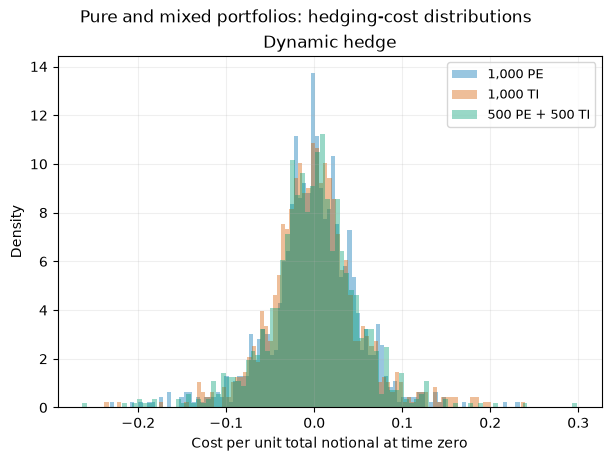

In [20]:
strategy_labels = dict(zip(cfe.STRATEGIES, cfe.LABELS))
units = {'aggregate': 'Aggregate cost at time zero', 'per_policy': 'Cost per policy at time zero',
         'per_notional': 'Cost per unit total notional at time zero'}
colors = {key: plot_settings['colors'][i % len(plot_settings['colors'])]
          for i, key in enumerate(portfolio_order)}

def finish_figure(fig, stem):
    if SAVE_FIGURES:
        for extension in analysis['figure_formats']:
            fig.savefig(RUN_DIRECTORY / f'{stem}.{extension}', dpi=analysis['dpi'])
    if SHOW_FIGURES:
        display(fig)
    plt.close(fig)

selected = plot_settings['strategies']
width, height = plot_settings['panel_size']
fig, axes = plt.subplots(1, len(selected), figsize=(width * len(selected), height),
                         squeeze=False, layout='constrained')
for ax, strategy in zip(axes[0], selected):
    si = cfe.STRATEGIES.index(strategy)
    full = cost_cube[:, :, si]
    limits = plot_settings['x_limits'].get(strategy)
    lo, hi = (float(full.min()), float(full.max())) if limits is None else limits
    if lo == hi:
        lo, hi = lo - .5, hi + .5
    grid = np.linspace(lo, hi, plot_settings['density_grid_points'])
    for pi, key in enumerate(portfolio_order):
        x = full[:, pi]
        if np.ptp(x) == 0:
            ax.axvline(x[0], color=colors[key], label=portfolio_labels[key] + ' (point mass)')
        elif plot_settings['density_method'] == 'histogram':
            ax.hist(x, bins=analysis['bins'], density=True, color=colors[key],
                    alpha=plot_settings['histogram_alpha'], label=portfolio_labels[key])
        else:
            density = gaussian_kde(x, bw_method=plot_settings['kde_bandwidth'])
            ax.plot(grid, density(grid), color=colors[key], label=portfolio_labels[key],
                    linewidth=plot_settings['line_width'])
    if limits is not None:
        ax.set_xlim(limits)
    ax.set(title=strategy_labels[strategy], xlabel=units[analysis['normalization']], ylabel='Density')
    ax.grid(alpha=.2)
    ax.legend(fontsize=9)
fig.suptitle('Pure and mixed portfolios: hedging-cost distributions')
finish_figure(fig, 'mixed_portfolio_density')


**CDFs and box plots.** The CDFs use complete samples without smoothing or bins.
Box plots summarize medians, interquartile ranges and tails. Hiding outliers
affects the graphic only. All exported statistics still use every scenario.


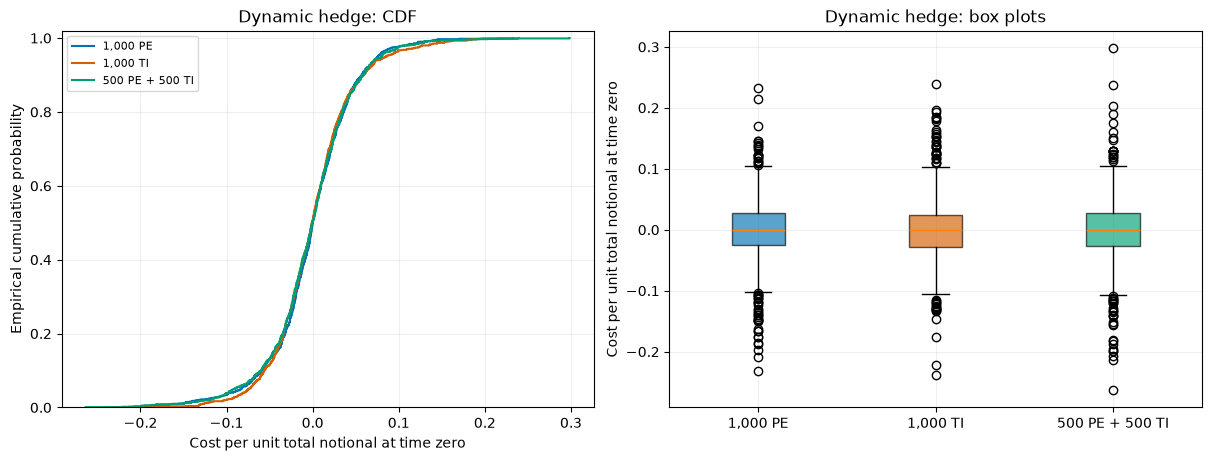

In [21]:
fig, axes = plt.subplots(len(selected), 2, figsize=(2 * width, height * len(selected)),
                         squeeze=False, layout='constrained')
for row_axes, strategy in zip(axes, selected):
    si = cfe.STRATEGIES.index(strategy)
    for pi, key in enumerate(portfolio_order):
        ordered = np.sort(cost_cube[:, pi, si])
        row_axes[0].step(ordered, np.arange(1, len(ordered) + 1) / len(ordered),
                         where='post', color=colors[key], label=portfolio_labels[key])
    row_axes[0].set(title=strategy_labels[strategy] + ': CDF',
                    xlabel=units[analysis['normalization']], ylabel='Empirical cumulative probability')
    row_axes[0].legend(fontsize=8)
    row_axes[0].set_ylim(0, 1.02)
    if plot_settings['x_limits'].get(strategy) is not None:
        row_axes[0].set_xlim(plot_settings['x_limits'][strategy])
    boxes = row_axes[1].boxplot([cost_cube[:, pi, si] for pi in range(len(portfolio_order))],
        patch_artist=True, showfliers=plot_settings['boxplot_show_fliers'],
        whis=plot_settings['boxplot_whiskers'])
    for patch, key in zip(boxes['boxes'], portfolio_order):
        patch.set_facecolor(colors[key])
        patch.set_alpha(.65)
    row_axes[1].set_xticks(range(1, len(portfolio_order) + 1))
    row_axes[1].set_xticklabels([portfolio_labels[key] for key in portfolio_order])
    row_axes[1].set(title=strategy_labels[strategy] + ': box plots',
                    ylabel=units[analysis['normalization']])
    for ax in row_axes:
        ax.grid(alpha=.2)
finish_figure(fig, 'mixed_portfolio_cdf_boxplots')


**Variance comparison and uncertainty.** Left panels show observed cost
variances. Right panels show the mixed portfolio's variance reduction against
each pure reference, with the individual bootstrap intervals when enabled.
Positive reductions favor the mixed portfolio. For a claim of reduction
against both benchmarks, inspect both comparisons; the intervals are not
simultaneous confidence statements.


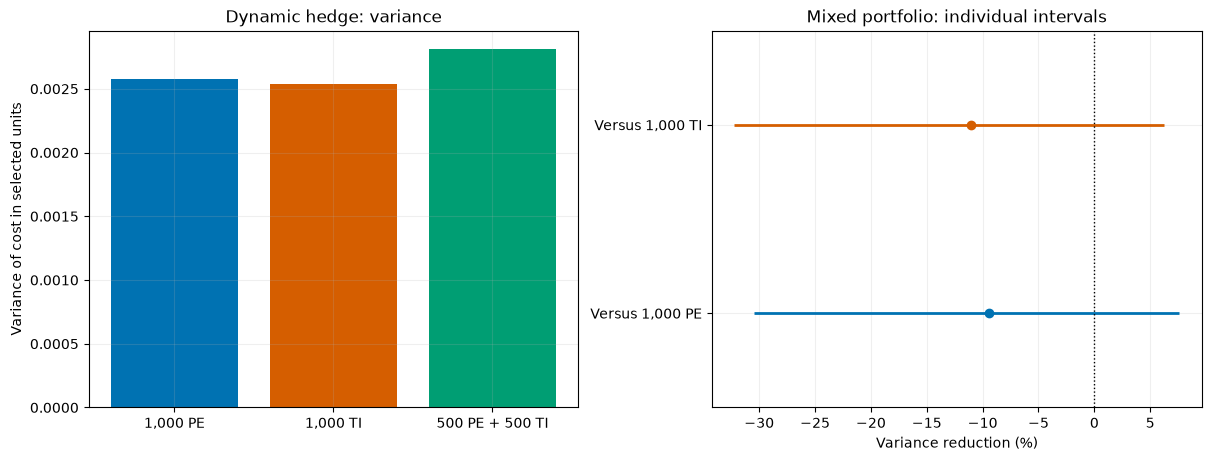

In [22]:
fig, axes = plt.subplots(len(selected), 2, figsize=(2 * width, height * len(selected)),
                         squeeze=False, layout='constrained')
for row_axes, strategy in zip(axes, selected):
    si = cfe.STRATEGIES.index(strategy)
    positions = np.arange(len(portfolio_order))
    values = variance_estimates[:, si]
    row_axes[0].bar(positions, values, color=[colors[key] for key in portfolio_order])
    row_axes[0].set_xticks(positions)
    row_axes[0].set_xticklabels([portfolio_labels[key] for key in portfolio_order])
    row_axes[0].set(title=strategy_labels[strategy] + ': variance',
                    ylabel='Variance of cost in selected units')
    if plot_settings['variance_log_scale'] and np.all(values > 0):
        row_axes[0].set_yscale('log')
    entries = [row for row in interval_rows if row['strategy'] == strategy]
    for y, row in enumerate(entries):
        if math.isfinite(row['VR_ci_low_percent']) and math.isfinite(row['VR_ci_high_percent']):
            row_axes[1].hlines(y, row['VR_ci_low_percent'], row['VR_ci_high_percent'],
                               color=colors[row['reference_id']], linewidth=2)
        row_axes[1].plot(row['VR_percent'], y, 'o', color=colors[row['reference_id']])
    row_axes[1].axvline(0, color='black', linestyle=':', linewidth=1)
    row_axes[1].set_yticks(range(len(entries)))
    row_axes[1].set_yticklabels(['Versus ' + row['reference'] for row in entries])
    row_axes[1].set(title='Mixed portfolio: individual intervals', xlabel='Variance reduction (%)')
    row_axes[1].set_ylim(-.5, len(entries) - .5)
    for ax in row_axes:
        ax.grid(alpha=.2)
finish_figure(fig, 'mixed_portfolio_variance_reduction')


**Interpret the result.** Same-age PE and TI exposures can offset when written
on the same life. Here they are on different lives. With $N$ equal-notional
independent lives and PE fraction $w$, the conditional mortality contribution
to unit-cost variance has the form
$[w v_{PE}+(1-w)v_{TI}]/N$, where each $v$ is the corresponding individual
conditional variance. This weighted average alone cannot be smaller than
both pure mortality components. Any additional reduction in total cost variance
depends on common-source exposures and their covariance.

The printed conclusion separates observed variance reduction from evidence
provided by the individual bootstrap intervals. All raw costs and analyses
remain saved for later investigation.


In [23]:
for strategy in selected:
    rows = [row for row in interval_rows if row['strategy'] == strategy]
    observed_both = all(row['variance_difference'] < 0 for row in rows)
    supported_each = all(math.isfinite(row['VR_ci_low_percent'])
                         and row['VR_ci_low_percent'] > 0 for row in rows)
    print(strategy_labels[strategy])
    print('  Observed mixed variance below both references:', observed_both)
    print('  Each individual bootstrap interval supports a reduction:', supported_each)
    print('  Individual intervals are not a simultaneous test of both comparisons.')
print('Saved experiment:', RUN_DIRECTORY)


Dynamic hedge
  Observed mixed variance below both references: False
  Each individual bootstrap interval supports a reduction: False
  Individual intervals are not a simultaneous test of both comparisons.
Saved experiment: /home/edoardolombardo/Documents/codes/CarbonFund_UL/results/mixed_pe_ti/cir_T20_PE_TI_500_500_01
